# Decoder loading stability across seeds — CosMx pancreas (Melton/Jimenez 2025)

The counterpart of `notebooks/legnini_23/4_a_decoder_stability.ipynb`, run on the melton25
gene-masking seed sweep **k0y6dgk6**. The selection code is the same module
(`src/decoder_stability.py`), deliberately: the two datasets are only comparable if the gene
selection is literally shared rather than reimplemented here.

---

## ⚠️ Read the sweep health check (first code section) before anything else

`k0y6dgk6` (2026-10-31) retrains the earlier seed sweep `4ztsppu8` on the current data. The old
checkpoints were trained on the 979-gene `melton25.h5ad` and cannot be loaded against
`melton25_pp.h5ad` (678 genes). The retrain also switched the mask rate to 0.5, selects
checkpoints on `val_r2`, and allows 200 epochs; the architecture is unchanged. Provenance:
`interscale/records/melton25/node_genemask/RECORD.md`, Stage 2a.

All five seeds finished, early-stopping at epochs 41–77, and none of them learned to
reconstruct:

| seed | val_r2 | val cosine | val mse | stop epoch |
|---|---|---|---|---|
| 40 | -0.0074 | 0.611 | 0.0291 | 41 |
| 41 | -0.0056 | 0.613 | 0.0289 | 53 |
| 42 | -0.0045 | 0.613 | 0.0290 | 60 |
| 43 | -0.0037 | 0.614 | 0.0289 | 77 |
| 44 | -0.0056 | 0.613 | 0.0290 | 52 |
| **mean ± sd** | **-0.0054 ± 0.0014** | 0.613 | 0.0290 | |

Against the bars measured on the same split and layer (RECORD.md):

| predictor | val_r2 | cosine | mse |
|---|---|---|---|
| constant per-gene train mean | -0.0007 | 0.615 | 0.0288 |
| per-cell-type mean | +0.0193 | 0.642 | 0.0273 |
| within-cell conditional Gaussian (gene masking's proper bar) | +0.0285 | | |

**Every seed is slightly *below* the constant per-gene mean.** The models converged onto the
mean predictor, consistently across seeds. Everything below still runs and the numbers are
real numbers about these checkpoints, but they are not a measurement of InterScale's loading
stability: a decoder with no signal has arbitrary loadings, so near-chance cross-seed overlap
is the *expected* result, and any dimension that looks structured is more likely reading
tissue geometry or composition than a learned gene programme. `collect_gene_sets` is called
with `allow_empty=True` for exactly this case.

In [1]:
import os
import sys
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import yaml
from scipy.sparse import issparse

import interscale

import warnings
warnings.filterwarnings("ignore")

In [2]:
# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print("LRZ cluster")
    CLUSTER = "LRZ"
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects"
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print("HPC cluster")
    CLUSTER = "HPC"
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/"
else:
    print("unknown")
    CLUSTER = "unknown"
DATA = "melton25"

HPC cluster


In [3]:
with open(os.path.join(BASE_DIR_REPO, "figures/config.yml"), "r") as f:
    config = yaml.safe_load(f)

PALETTE = config["palettes"]["continuous"]

# config.yml keys these by the condition NAME the paper uses; the obs column spells them
# "ND" and "T1D". 1_12 is the ND fov, 1_10 the T1D one.
slides = config["slide_examples"]["Melton_Jimenez"]
EXAMPLE_FOVS = [slides["Ctrl"], slides["T1D"]]
print("example fovs:", EXAMPLE_FOVS)

example fovs: ['1_12', '1_10']


## Load data

In [4]:
MELTON25 = f"{BASE_DIR_PROJECT}/data/{DATA}_pp.h5ad"
adata = sc.read_h5ad(MELTON25)
adata

AnnData object with n_obs × n_vars = 386727 × 678
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.GCG', 'Max.GCG', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'cell_ID', 'condition', 'slide', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_NegPrb', 'log1p_total_counts_NegPrb', 'pct_counts_NegPrb', 'n_genes', 'cell_type_coarse', 'CellTypes_max', 'slide_fov', 'slide_condition', 'split', 'split_0', 'split_1', 'split_2', 'globalX', 'globalY', 'sliding_window_square', 'sliding_window_h', 'sliding_window_v', 'split_mixed', 'split_fov'
    obsm: 'X_pca', 'X_umap', 'spatial', 'spatial_fov'
    layers: 'counts', 'log1p_norm', 'log1p_slide_fov_c', 'log1p_slide_fov_z', None (.X)

In [5]:
# The keys this notebook leans on, named once so a change in the file shows up here and not
# twenty cells down.
SAMPLE_KEY = "slide_fov"            # the tissue section: 71 of them, the unit anchors live in
CONDITION_KEY = "condition"         # ND / T1D
LAYER_KEY = "log1p_norm"            # what node_reg trains against (see registry.yaml)

print(adata.obs[CONDITION_KEY].value_counts().to_string())
print(f"\n{adata.obs[SAMPLE_KEY].nunique()} {SAMPLE_KEY} sections, "
      f"median {int(adata.obs[SAMPLE_KEY].value_counts().median())} cells")
print("layers:", list(adata.layers))
print("zero-count cells:", int((adata.layers['counts'].sum(1) == 0).sum()))

condition
T1D    225288
ND     161439

71 slide_fov sections, median 5378 cells
layers: ['counts', 'log1p_norm', 'log1p_slide_fov_c', 'log1p_slide_fov_z', None]
zero-count cells: 0


## Sweep and arm

Only the **gene-masking** arm exists for melton25 so far (sweep `k0y6dgk6`, which supersedes
`4ztsppu8`). The cell-masking
entry is left in place but empty: fill in its sweep id and flip `MASKING` to run the same
comparison legnini23 makes between the two arms.

In [6]:
project_root = Path(BASE_DIR_REPO)
sys.path.insert(0, str(project_root))

# interscale is a SIBLING of InterScale_reproducibility, not a subdirectory.
INTERSCALE_REPO = project_root.parent / "interscale"
REGISTRY = INTERSCALE_REPO / "config_files" / "registry.yaml"

DATASET = "melton25"

MASKING = "gene"   # "gene" | "cell"

ARMS = {
    "gene": {
        "task": "node_reg_genemask",
        # k0y6dgk6 retrains 4ztsppu8 on melton25_pp (678 genes); 4ztsppu8 was trained on the
        # 979-gene melton25.h5ad and cannot be loaded against it. The sweep pins
        # mask_percentage 0.5 itself, so SWEEP_OVERRIDES reapplies it -- no arm override.
        # See interscale/records/melton25/node_genemask/RECORD.md, Stage 2a.
        "sweep_id": "k0y6dgk6",
        "overrides": {},
    },
    "cell": {
        "task": "node_reg",
        "sweep_id": None,   # <- no cell-masking seed sweep for melton25 yet
        "overrides": {},
    },
}
ARM = ARMS[MASKING]
TASK, SWEEP_ID = ARM["task"], ARM["sweep_id"]
assert SWEEP_ID, (
    f"no sweep id recorded for the {MASKING!r} arm of melton25. Train one, or set "
    f"MASKING = 'gene' (sweep k0y6dgk6)."
)

ARTIFACT_DIR = Path(BASE_DIR_PROJECT) / "wandb_artifacts"
RESULTS_DIR = Path(BASE_DIR_PROJECT) / "results" / DATA / f"rec_seed_stablity_{MASKING}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"masking     {MASKING} (task {TASK}, sweep {SWEEP_ID})")
print(f"registry    {REGISTRY}\nartifacts   {ARTIFACT_DIR}\nresults     {RESULTS_DIR}")

masking     gene (task node_reg_genemask, sweep k0y6dgk6)
registry    /home/icb/francesca.drummer/1-Projects/A3_InterScale/interscale/config_files/registry.yaml
artifacts   /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/wandb_artifacts
results     /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25/rec_seed_stablity_gene


In [7]:
import wandb

from src.wandb import Wandb_evaluation, sweep_checkpoint_loader

from src.decoder_stability import (
    build_cfg as _build_cfg,
    collect_gene_sets,
    dim_embedding_adata,
    dim_names,
    expected_intersection,
    local_global_split,
    overlap_matrix,
    plot_dim_gene_spatial,
    plot_intersection_by_k,
    plot_tail_prob_by_k,
    run_seed_inference,
    top_genes_per_dim,
)

wandb.login()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /home/icb/francesca.drummer/.netrc.


wandb: Currently logged in as: francesca-drummer to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


True

### What the sweep pinned

**This sweep is not a seeds-only sweep.** Unlike the legnini23 ones, `k0y6dgk6` pins a whole
architecture that differs from the melton25 registry defaults — `model.n_embed` 128 against
the registry's 16, `model.local_component.parameters.num_layers` 1 against 2, plus the loss,
lr, widths, mask rate, monitor and arm name (`dataset.name: melton25_genemask_r5em1`).
Rebuilding the config from the registry alone would produce a model of the
wrong shape, and `sweep_checkpoint_loader(verify=True)` would refuse to load the weights
into it.

So the overrides are read from the sweep itself rather than copied by hand: every parameter
the sweep fixed to a single value is reapplied, and only `optim.seed` (set per trial by
`build_cfg`) and `model.save` (a training path; the checkpoints come from artifacts) are
dropped. A future retrain with different hyperparameters needs no edit here.

In [8]:
_api = wandb.Api(timeout=60)
_sweep = _api.sweep(f"francesca-drummer/InterScale_hyperparameter_sweep/{SWEEP_ID}")

SKIP = {"optim.seed", "model.save"}
SWEEP_OVERRIDES, SWEPT = {}, {}
for _k, _spec in _sweep.config.get("parameters", {}).items():
    _vals = _spec.get("values", [_spec["value"]] if "value" in _spec else [])
    if _k in SKIP:
        SWEPT[_k] = _vals
        continue
    if len(_vals) == 1:
        SWEEP_OVERRIDES[_k] = _vals[0]
    else:
        SWEPT[_k] = _vals

print(f"{len(SWEEP_OVERRIDES)} parameters pinned by the sweep, reapplied to every config:")
for _k, _v in sorted(SWEEP_OVERRIDES.items()):
    print(f"  {_k:52s} {_v}")
if SWEPT:
    print("\nvaried across trials (or handled elsewhere):")
    for _k, _v in sorted(SWEPT.items()):
        print(f"  {_k:52s} {_v}")

18 parameters pinned by the sweep, reapplied to every config:
  dataset.batch_size                                   8
  dataset.mask_percentage                              0.5
  dataset.name                                         melton25_genemask_r5em1
  model.global_component.parameters.dim_feedforward    256
  model.global_component.parameters.dropout_global     0
  model.global_component.parameters.n_heads            2
  model.global_component.parameters.num_layers         2
  model.local_component.parameters.dropout_local       0
  model.local_component.parameters.hidden_dim          256
  model.local_component.parameters.num_layers          1
  model.n_embed                                        128
  optim.loss                                           GaussianNLL
  optim.lr                                             0.005
  optim.lr_warmup                                      20
  optim.monitor                                        val_r2
  optim.n_epochs                 

### Sweep health check

<mark>This is the gate. Everything below is conditional on it.</mark>

`val_r2` is what `k0y6dgk6` optimised and selected checkpoints on. Its zero is the constant
per-gene mean, so a model has to clear that before its decoder carries anything; the
cell-type and within-cell bars (RECORD.md) are what it would have to clear before a loading
could be read as *spatial*. The loadings of a decoder that cannot reconstruct are arbitrary,
and their cross-seed overlap measures nothing about the method.

In [9]:
sweep_eval = Wandb_evaluation(
    "InterScale",
    SWEEP_ID,
    local_component=True,
    global_component=True,
    sweep_goal="robustness",
    classes=[None],
)
sweep_df = sweep_eval.get_dataframe()
sweep_df.head()

,id,name,seed,state,mask_percentage,mask_strategy,pct_mask_nodes,radius,decoder_type,runtime_seconds,total_parameters,test_r2,test_pearson_corr
0,im44jmd1,dual_melton25_genemask_r5em1_regr_node_40_GCN_...,40,finished,0.5,gene,0.5,None,None,168,614604,-0.009818,0.001954
1,oahvf9zq,dual_melton25_genemask_r5em1_regr_node_41_GCN_...,41,finished,0.5,gene,0.5,None,None,203,614604,-0.007900,0.003948
2,aisbalma,dual_melton25_genemask_r5em1_regr_node_42_GCN_...,42,finished,0.5,gene,0.5,None,None,228,614604,-0.006891,0.007717
3,bzpxwz1k,dual_melton25_genemask_r5em1_regr_node_43_GCN_...,43,finished,0.5,gene,0.5,None,None,292,614604,-0.005997,0.009065
4,w4126mwc,dual_melton25_genemask_r5em1_regr_node_44_GCN_...,44,finished,0.5,gene,0.5,None,None,205,614604,-0.008328,0.003697


In [10]:
# Read off the run summaries: Wandb_evaluation's dataframe does not carry the val_ metrics.
# Bars measured on split_fov / val / log1p_norm (interscale/records/melton25/node_genemask/RECORD.md).
R2_BARS = {
    "constant per-gene mean": -0.0007,
    "per-cell-type mean": 0.0193,
    "within-cell conditional Gaussian": 0.0285,   # gene masking's proper, non-spatial bar
}
MIN_VAL_R2 = R2_BARS["constant per-gene mean"]   # at or below this the decoder carries nothing

health = []
for _r in _sweep.runs:
    _s = _r.summary
    health.append({
        "seed": _r.config.get("optim.seed"),
        "state": _r.state,
        "epochs": _s.get("epoch"),
        "val_r2": _s.get("val_r2"),
        "val_cosine": _s.get("val_cosine_similarity"),
        "val_mse": _s.get("val_mse"),
        "val_concordance_corr": _s.get("val_concordance_corr"),
        "test_r2": _s.get("test_r2"),
    })
health = pd.DataFrame(health).sort_values("seed").reset_index(drop=True)
print(health.round(4).to_string(index=False))

vals = pd.to_numeric(health["val_r2"], errors="coerce")
med = float(vals.median())
print(f"\nval_r2 {vals.mean():+.4f} +/- {vals.std():.4f} (median {med:+.4f})")
for _name, _bar in R2_BARS.items():
    print(f"  dR2 vs {_name:34s} ({_bar:+.4f}): {med - _bar:+.4f}")

HEALTHY = med > MIN_VAL_R2
if not HEALTHY:
    print(
        "\n" + "=" * 88
        + "\n!! THE MODELS IN THIS SWEEP DID NOT LEARN TO RECONSTRUCT."
        + f"\n!! median val_r2 = {med:+.4f}, at or below the constant per-gene mean ({MIN_VAL_R2:+.4f})."
        + "\n!!"
        "\n!! Everything below still runs and the numbers are real, but they describe THESE"
        "\n!! CHECKPOINTS, not InterScale's loading stability. Near-chance cross-seed overlap"
        "\n!! is the expected outcome of arbitrary loadings and is not evidence about the"
        "\n!! method.\n"
        + "=" * 88
    )
elif med <= R2_BARS["within-cell conditional Gaussian"]:
    print("\nabove the constant mean but below the within-cell bar: the decoders carry signal,"
          "\nbut not demonstrably spatial signal -- read the loadings as co-expression.")
else:
    print("\nsweep clears the within-cell bar -- the analysis below is interpretable.")

 seed    state  epochs  val_r2  val_cosine  val_mse  val_concordance_corr  test_r2
   40 finished      41 -0.0074      0.6108   0.0291                0.0002  -0.0098
   41 finished      53 -0.0056      0.6130   0.0290                0.0004  -0.0079
   42 finished      60 -0.0045      0.6131   0.0290                0.0008  -0.0069
   43 finished      77 -0.0037      0.6138   0.0289                0.0011  -0.0060
   44 finished      52 -0.0056      0.6128   0.0290                0.0004  -0.0083

val_r2 -0.0054 +/- 0.0014 (median -0.0056)
  dR2 vs constant per-gene mean             (-0.0007): -0.0049
  dR2 vs per-cell-type mean                 (+0.0193): -0.0249
  dR2 vs within-cell conditional Gaussian   (+0.0285): -0.0341

!! THE MODELS IN THIS SWEEP DID NOT LEARN TO RECONSTRUCT.
!! median val_r2 = -0.0056, at or below the constant per-gene mean (-0.0007).
!!
!! Everything below still runs and the numbers are real, but they describe THESE
!! CHECKPOINTS, not InterScale's loading stabili

## Model inference

Loads each seed's checkpoint from its wandb artifact and writes
`obsm[f"{seed}_{{local,global}}_emb"]` plus `layers[f"{seed}_y_pred_*"]` into `adata`.

**This is the expensive cell**: 386k cells against five models. Run it on a compute node.

In [11]:
# `optim.n_epochs` is 100 in the melton25 configs; every run early-stopped at epoch 40.
# Reapplying 100 reproduces the config each trial was launched with, which is what
# get_model_filename_prefix is checked against before the weights are touched.
# SWEEP_OVERRIDES carries everything the sweep pinned (n_embed 128, local num_layers 1, the
# loss, the widths); ARM["overrides"] is applied last so an arm-specific value wins.
build_cfg = partial(
    _build_cfg,
    DATASET,
    TASK,
    REGISTRY,
    models_dir=ARTIFACT_DIR,
    overrides={"optim.n_epochs": 100, **SWEEP_OVERRIDES, **ARM["overrides"]},
)

In [12]:
from interscale.tl import remove_zero_expression_cells

# Training filtered zero-expression cells, so inference has to filter identically or the
# per-window graphs handed to the model are not the graphs it was trained on.
#
# melton25_pp.h5ad keeps raw counts in `counts` (legnini23 calls the same layer `raw`), and
# .X is NOT log1p_norm here -- the registry comment records .X running to 4.39 against
# log1p_norm's 2.55. Restoring counts first makes this cell order-independent.
adata.X = adata.layers["counts"]
adata = remove_zero_expression_cells(adata)

SEEDS = sorted(sweep_df["seed"].astype(int))
print("seeds:", SEEDS)

cfg0 = build_cfg(SEEDS[0])
window_key = cfg0.dataset.sample_key[0]     # sliding_window_square
assert cfg0.model.decoder.dual_decoder, (
    "cfg has no local decoder, so there is nothing to compare against the global one"
)

sizes = adata.obs[window_key].value_counts()
sizes = sizes[sizes > 0]
assert sizes.max() <= cfg0.model.global_component.parameters.max_seq_len, (
    f"largest {window_key} graph is {sizes.max()} cells but max_seq_len is "
    f"{cfg0.model.global_component.parameters.max_seq_len}"
)
print(f"{len(sizes)} graphs over '{window_key}', largest {sizes.max()} cells "
      f"(max_seq_len {cfg0.model.global_component.parameters.max_seq_len})")
print(f"layer_key {cfg0.dataset.layer_key} | n_embed {cfg0.model.n_embed} | "
      f"radius {cfg0.dataset.spatial_neigbors_kwargs.radius}")

_y_true = adata.layers[cfg0.dataset.layer_key]
y_true = np.asarray(_y_true.todense() if issparse(_y_true) else _y_true, dtype=np.float64)

Nr. of zero expression cells: 0
seeds: [40, 41, 42, 43, 44]


596 graphs over 'sliding_window_square', largest 1600 cells (max_seq_len 1600)
layer_key log1p_norm | n_embed 128 | radius 110


In [13]:
load_from_sweep = sweep_checkpoint_loader(
    SWEEP_ID,
    ARTIFACT_DIR,
    run_ids=dict(zip(sweep_df["seed"].astype(int), sweep_df["id"])),
)

sweep k0y6dgk6: seed 40 -> im44jmd1, seed 41 -> oahvf9zq, seed 42 -> aisbalma, seed 43 -> bzpxwz1k, seed 44 -> w4126mwc


In [14]:
adata, models, local_emb, global_emb, performance = run_seed_inference(
    adata,
    SEEDS,
    build_cfg,
    None,            # checkpoints come from wandb, not a local directory
    RESULTS_DIR,
    load_model=load_from_sweep,
    y_true=y_true,
    repro_seed=40,
)

wandb:   1 of 1 files downloaded.  


converted model.ckpt -> /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/wandb_artifacts/im44jmd1/model.pt


Loading model from /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/wandb_artifacts/im44jmd1/model.pt
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown


Load GEX from .layers/log1p_norm
INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


... (2,986 outputs left out)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  



seed 44: wrote model_44_performance.csv (5424 rows)
  per-gene medians on the test split:
               r2       mse   pearson  cosine_sim
decoder                                          
global  -0.525898  0.032255  0.002339   -0.020855
local   -1.077916  0.041025  0.007829   -0.153394

embeddings: local (386727, 128), global (386727, 128) per seed


## Gene loadings

**`dims="all"` is wrong for this dataset.** melton25 trains `n_embed = 128` against a
678-gene panel, so scoring every dimension at `n_top=3` can select up to 384 genes — 57% of
the panel — and seeds would then agree largely because each set is half the panel. This is
the exact case `collect_gene_sets`' `dims` docstring warns about, and the published CosMx
figure reads its loadings off a handful of dimensions instead. So: `dims=None` with a
cumulative importance cutoff.

In [15]:
from interscale.evaluation import calculate_dim_importance, gene_loadings, get_genes_dim

SEED = SEEDS[-2]
CUMULATIVE_CUTOFF = 0.6
print(f"seed {SEED} | panel {adata.n_vars} genes | n_embed {cfg0.model.n_embed}")

seed 43 | panel 678 genes | n_embed 128



60% cumulative variance reached with 50 dimensions:
Embedding dimensions (sorted by importance):
[25, 22, 11, 66, 45, 30, 118, 53, 105, 107, 99, 80, 34, 72, 7, 47, 82, 121, 77, 91, 48, 59, 68, 67, 101, 93, 92, 97, 122, 98, 70, 81, 87, 69, 57, 29, 110, 60, 9, 19, 73, 94, 40, 120, 39, 23, 124, 50, 55, 1]

60% cumulative variance reached with 50 dimensions:
Embedding dimensions (sorted by importance):
[66, 30, 25, 34, 22, 124, 100, 95, 118, 9, 57, 11, 105, 56, 45, 91, 82, 16, 7, 110, 40, 79, 93, 54, 53, 68, 86, 97, 99, 60, 46, 103, 77, 19, 81, 47, 120, 121, 102, 23, 51, 114, 87, 32, 69, 89, 71, 1, 39, 0]


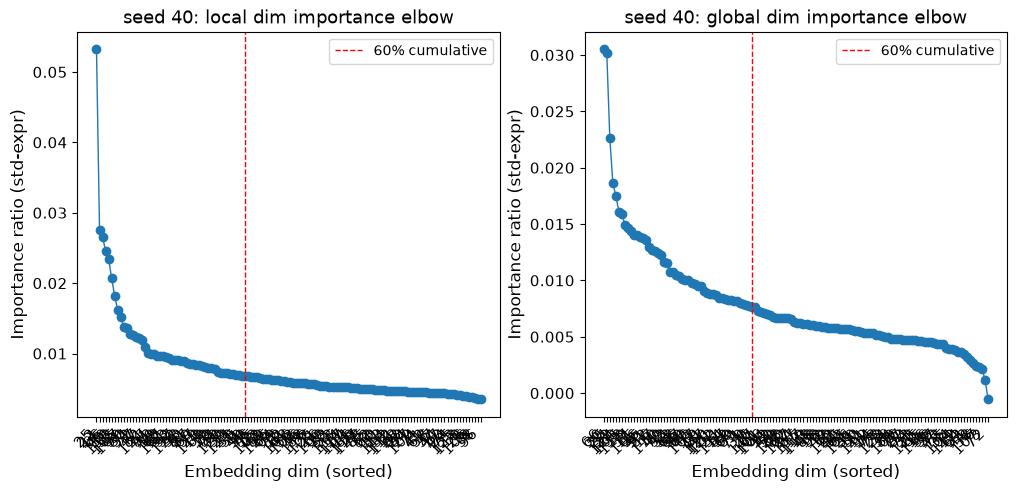

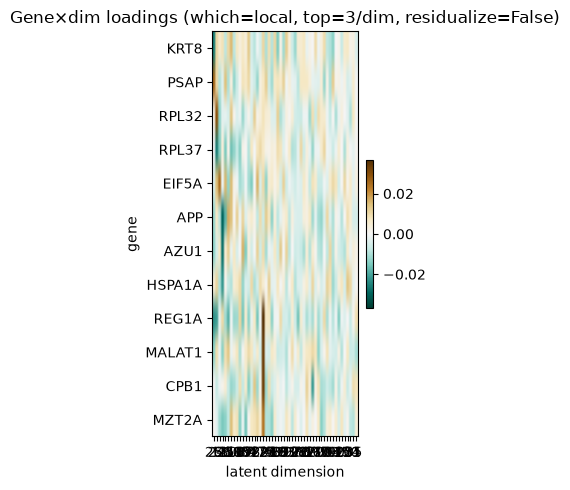

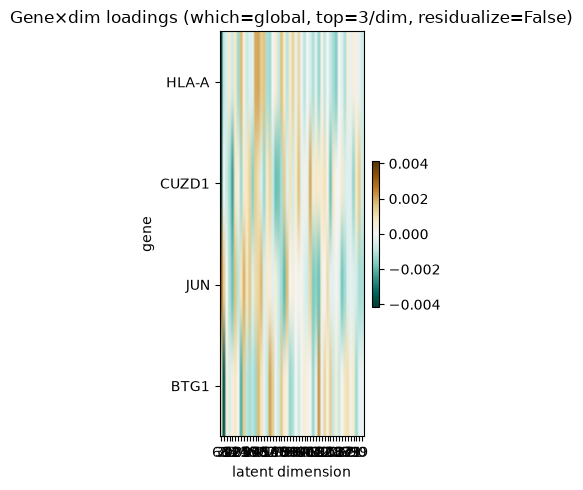

seed 40 local :  12 genes off 50 dims [np.int64(1), np.int64(7), np.int64(9), np.int64(11), np.int64(19), np.int64(22), np.int64(23), np.int64(25), np.int64(29), np.int64(30), np.int64(34), np.int64(39)] ...
seed 40 global:   4 genes off 50 dims [np.int64(0), np.int64(1), np.int64(7), np.int64(9), np.int64(11), np.int64(16), np.int64(19), np.int64(22), np.int64(23), np.int64(25), np.int64(30), np.int64(32)] ...



60% cumulative variance reached with 30 dimensions:
Embedding dimensions (sorted by importance):
[108, 119, 87, 44, 62, 64, 82, 25, 98, 118, 76, 114, 31, 80, 32, 57, 65, 107, 21, 0, 106, 125, 36, 26, 68, 110, 38, 63, 54, 2]

60% cumulative variance reached with 28 dimensions:
Embedding dimensions (sorted by importance):
[108, 119, 88, 1, 44, 62, 8, 25, 65, 51, 10, 87, 36, 54, 31, 21, 26, 22, 57, 13, 84, 118, 98, 41, 82, 39, 86, 78]


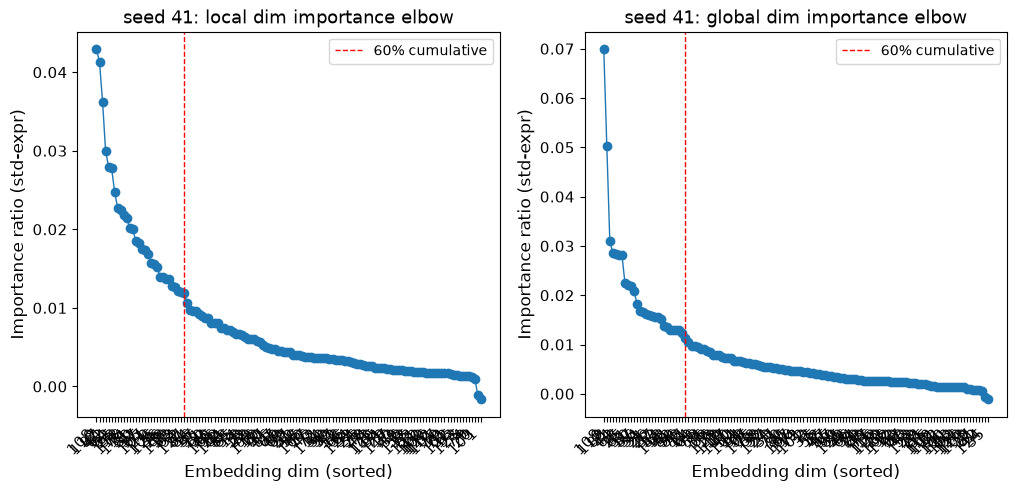

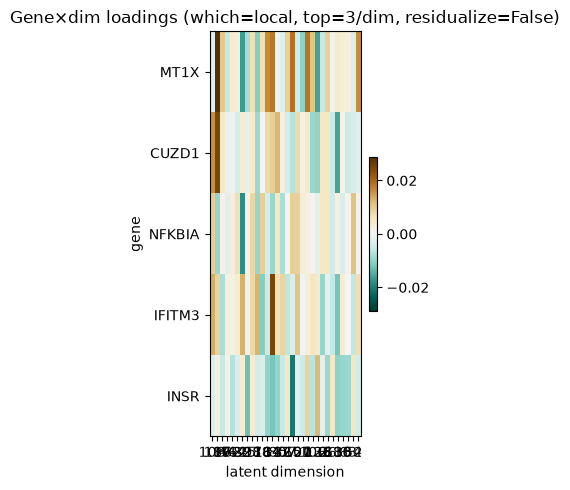

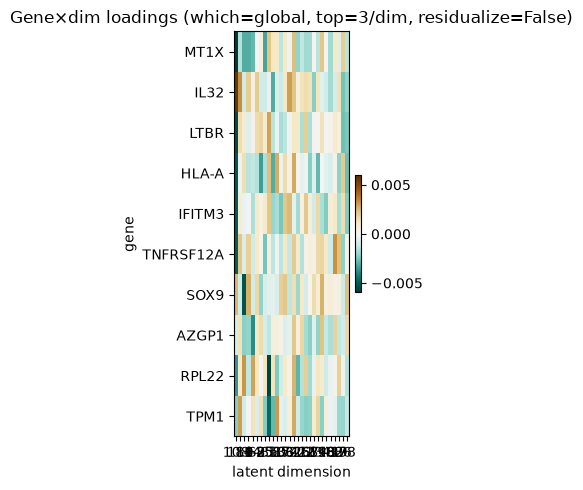

seed 41 local :   5 genes off 30 dims [np.int64(0), np.int64(2), np.int64(21), np.int64(25), np.int64(26), np.int64(31), np.int64(32), np.int64(36), np.int64(38), np.int64(44), np.int64(54), np.int64(57)] ...
seed 41 global:  10 genes off 28 dims [np.int64(1), np.int64(8), np.int64(10), np.int64(13), np.int64(21), np.int64(22), np.int64(25), np.int64(26), np.int64(31), np.int64(36), np.int64(39), np.int64(41)] ...



60% cumulative variance reached with 23 dimensions:
Embedding dimensions (sorted by importance):
[66, 17, 86, 127, 65, 15, 50, 90, 32, 101, 59, 24, 82, 5, 120, 102, 27, 63, 60, 14, 109, 118, 119]

60% cumulative variance reached with 23 dimensions:
Embedding dimensions (sorted by importance):
[52, 66, 17, 50, 86, 109, 99, 126, 16, 71, 28, 69, 41, 59, 27, 65, 87, 15, 1, 61, 101, 127, 22]


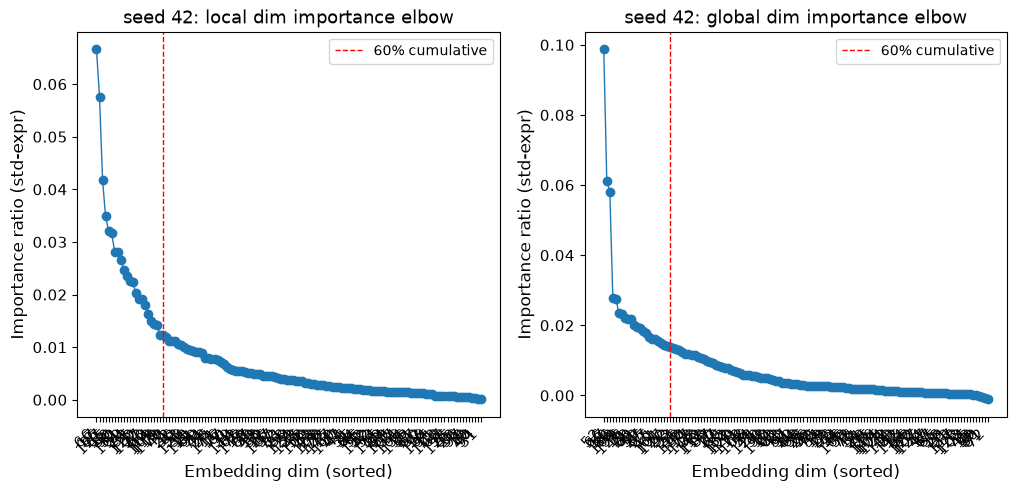

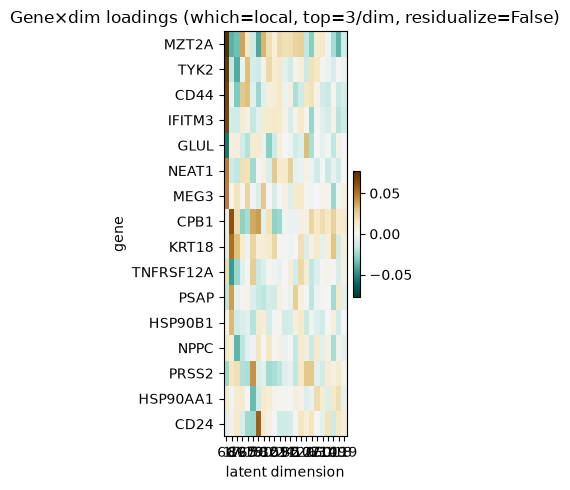

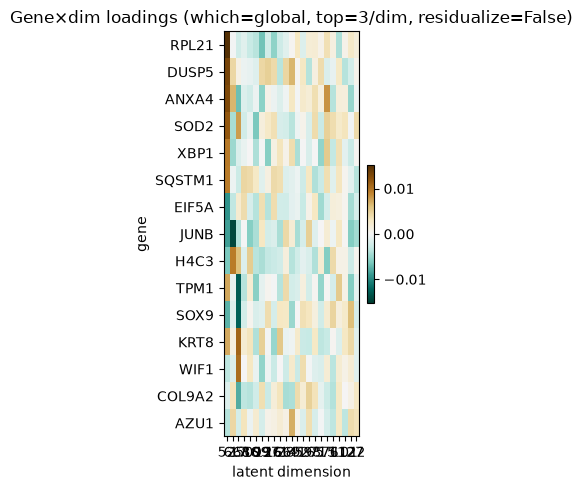

seed 42 local :  16 genes off 23 dims [np.int64(5), np.int64(14), np.int64(15), np.int64(17), np.int64(24), np.int64(27), np.int64(32), np.int64(50), np.int64(59), np.int64(60), np.int64(63), np.int64(65)] ...
seed 42 global:  15 genes off 23 dims [np.int64(1), np.int64(15), np.int64(16), np.int64(17), np.int64(22), np.int64(27), np.int64(28), np.int64(41), np.int64(50), np.int64(52), np.int64(59), np.int64(61)] ...



60% cumulative variance reached with 19 dimensions:
Embedding dimensions (sorted by importance):
[35, 72, 43, 58, 99, 114, 108, 22, 13, 126, 68, 38, 51, 39, 123, 50, 77, 1, 27]

60% cumulative variance reached with 21 dimensions:
Embedding dimensions (sorted by importance):
[72, 35, 52, 22, 99, 77, 126, 123, 58, 114, 71, 108, 68, 16, 101, 8, 88, 91, 44, 97, 3]


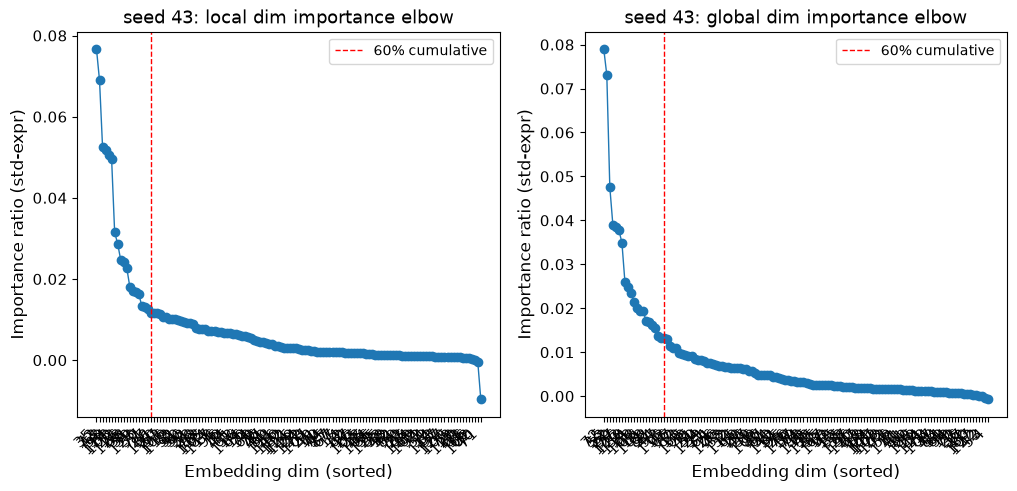

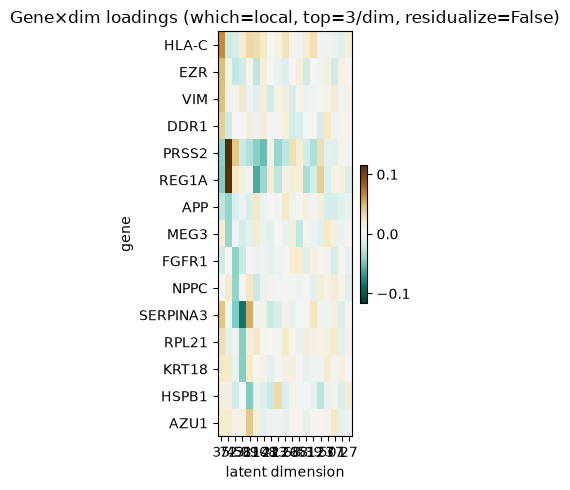

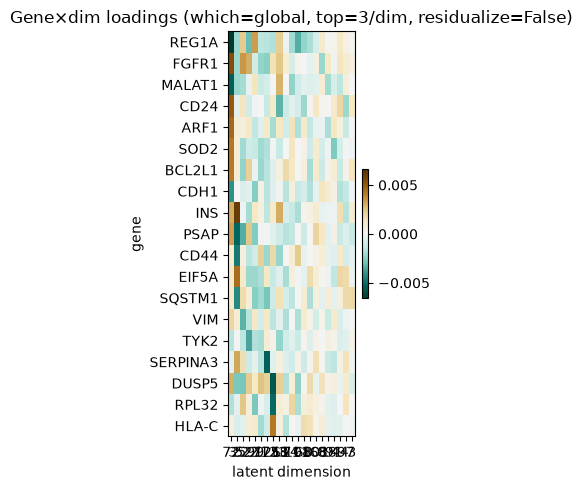

seed 43 local :  15 genes off 19 dims [np.int64(1), np.int64(13), np.int64(22), np.int64(27), np.int64(35), np.int64(38), np.int64(39), np.int64(43), np.int64(50), np.int64(51), np.int64(58), np.int64(68)] ...
seed 43 global:  19 genes off 21 dims [np.int64(3), np.int64(8), np.int64(16), np.int64(22), np.int64(35), np.int64(44), np.int64(52), np.int64(58), np.int64(68), np.int64(71), np.int64(72), np.int64(77)] ...



60% cumulative variance reached with 30 dimensions:
Embedding dimensions (sorted by importance):
[2, 0, 41, 74, 44, 3, 25, 46, 82, 15, 57, 101, 110, 4, 7, 61, 22, 27, 18, 53, 123, 66, 125, 24, 98, 73, 59, 60, 43, 106]

60% cumulative variance reached with 36 dimensions:
Embedding dimensions (sorted by importance):
[25, 2, 3, 110, 46, 82, 114, 22, 53, 0, 24, 44, 123, 115, 17, 101, 74, 41, 57, 66, 61, 56, 35, 62, 55, 73, 37, 69, 4, 15, 100, 109, 10, 60, 89, 9]


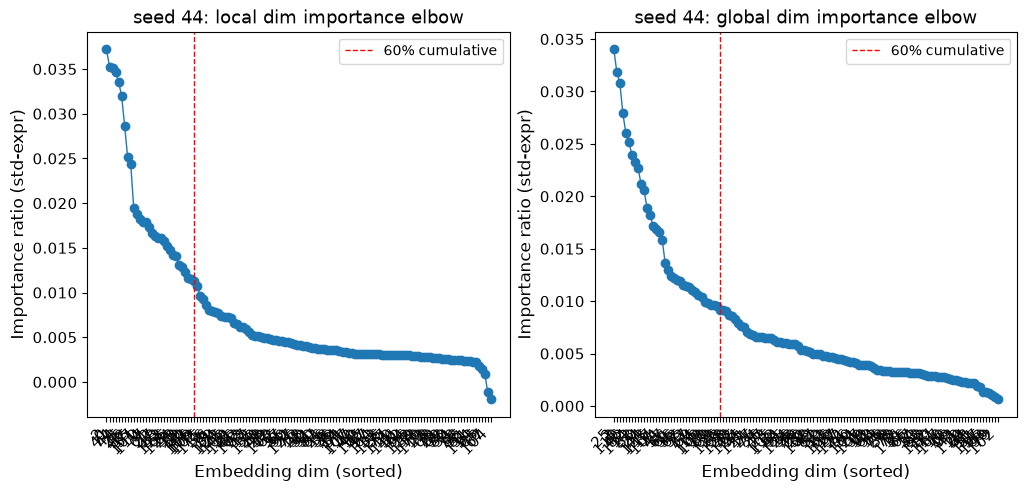

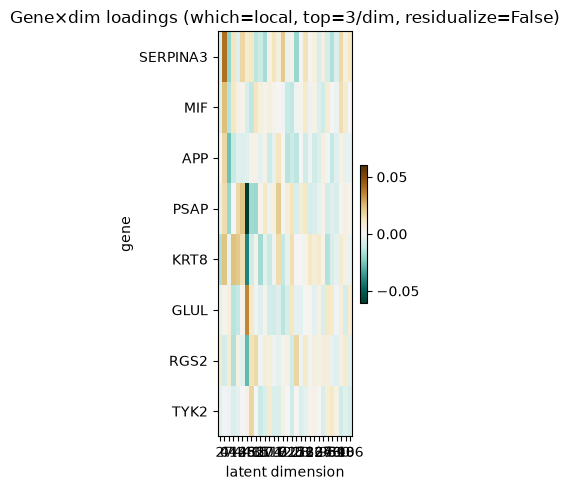

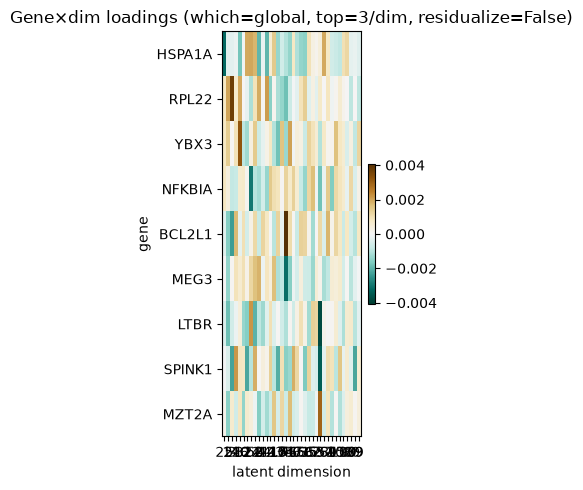

seed 44 local :   8 genes off 30 dims [np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(7), np.int64(15), np.int64(18), np.int64(22), np.int64(24), np.int64(25), np.int64(27), np.int64(41)] ...
seed 44 global:   9 genes off 36 dims [np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(9), np.int64(10), np.int64(15), np.int64(17), np.int64(22), np.int64(24), np.int64(25), np.int64(35)] ...


In [16]:
df_local_list, df_global_list, dims_used = collect_gene_sets(
    adata,
    models,
    SEEDS,
    layer_key=LAYER_KEY,
    n_embed=cfg0.model.n_embed,
    dims=None,                 # read the stored selection, NOT every dimension
    n_top=3,
    rank_by="loading_x_sd",
    min_frac=0.2,
    enforce_specificity=True,
    specificity_min=1.5,
    cumulative_cutoff=CUMULATIVE_CUTOFF,
    spacing=2,
    # A decoder with no signal has no dimension-specific programme, and get_genes_dim raises
    # "No genes passed specificity filter" when none exists. On this sweep that is the
    # EXPECTED outcome, not a crash to work around: allow_empty turns it into an empty set
    # per (seed, component) with a named warning, so one failure does not discard the others.
    allow_empty=True,
    plot=True,
)

In [17]:
sizes = pd.DataFrame({
    "seed": SEEDS,
    "n_local": [len(d) for d in df_local_list],
    "n_global": [len(d) for d in df_global_list],
    "dims_local": [len(dims_used["local"][s]) for s in SEEDS],
    "dims_global": [len(dims_used["global"][s]) for s in SEEDS],
})
print(sizes.to_string(index=False))
if sizes[["n_local", "n_global"]].to_numpy().sum() == 0:
    print("\n!! every (seed, component) selection came back EMPTY -- no dimension carries a\n"
          "!! gene programme in these checkpoints. That is the health check's prediction, and\n"
          "!! nothing below this point has anything to measure.")

 seed  n_local  n_global  dims_local  dims_global
   40       12         4          50           50
   41        5        10          30           28
   42       16        15          23           23
   43       15        19          19           21
   44        8         9          30           36


## Cross-seed stability

No published melton25 gene list exists to score recall against — legnini23's
`plot_membership` panels have no counterpart here — so the read-out is cross-seed agreement
alone, against the overlap a random selection of the same set sizes would already produce.

In [18]:
exp_intersection = {}
for df_list, component in [(df_local_list, "local"), (df_global_list, "global")]:
    exp_intersection[component] = expected_intersection(
        [len(df.index) for df in df_list], pool=adata.n_vars
    )
exp_intersection

{'local': 5.45172202381668e-07, 'global': 4.855439927461731e-07}

,group,k,n_subsets,obs_mean,obs_sd,obs_min,obs_max,exp_mean,fold_mean
0,local,2,10,1.9,1.523884,0.0,4.0,1.786136e-01,10.637490
1,local,3,10,0.2,0.421637,0.0,1.0,2.731442e-03,73.221408
2,local,4,5,0.0,0.000000,0.0,0.0,3.973488e-05,0.000000
3,local,5,1,0.0,0.000000,0.0,0.0,5.451722e-07,0.000000
0,global,2,10,1.0,1.333333,0.0,4.0,1.818584e-01,5.498783
1,global,3,10,0.0,0.000000,0.0,0.0,2.732094e-03,0.000000
2,global,4,5,0.0,0.000000,0.0,0.0,3.821402e-05,0.000000
3,global,5,1,0.0,0.000000,0.0,0.0,4.855440e-07,0.000000


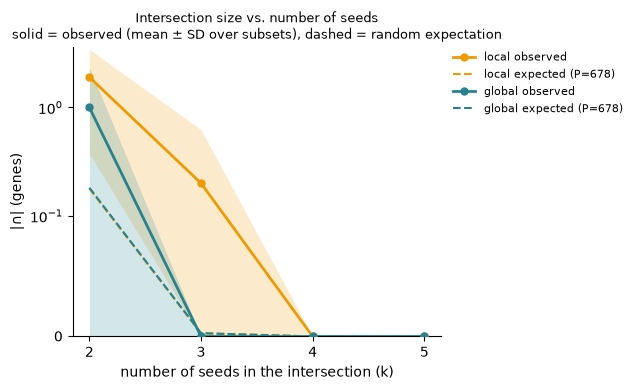

In [19]:
POOL = adata.n_vars   # 678; min_frac=0.2 filters this down, so this is the permissive bound
plot_intersection_by_k({"local": df_local_list, "global": df_global_list}, pool=POOL, log=True)

,group,k,n_subsets,p_mean,p_median,p_sd,p_min,p_max,obs_mean,exp_mean,fold_mean,method,n_iter
0,local,2,10,0.312957,0.006973,0.475333,0.000227,1.0,1.9,1.786136e-01,9.004687,hypergeometric,0
1,local,3,10,0.800630,1.000000,0.420309,0.003050,1.0,0.2,2.731442e-03,61.849844,monte-carlo,20000
2,local,4,5,1.000000,1.000000,0.000000,1.000000,1.0,0.0,3.973488e-05,0.000000,monte-carlo,20000
3,local,5,1,1.000000,1.000000,0.000000,1.000000,1.0,0.0,5.451722e-07,0.000000,monte-carlo,20000
0,global,2,10,0.531049,0.613454,0.498341,0.000497,1.0,1.0,1.818584e-01,5.453737,hypergeometric,0
1,global,3,10,1.000000,1.000000,0.000000,1.000000,1.0,0.0,2.732094e-03,0.000000,monte-carlo,20000
2,global,4,5,1.000000,1.000000,0.000000,1.000000,1.0,0.0,3.821402e-05,0.000000,monte-carlo,20000
3,global,5,1,1.000000,1.000000,0.000000,1.000000,1.0,0.0,4.855440e-07,0.000000,monte-carlo,20000


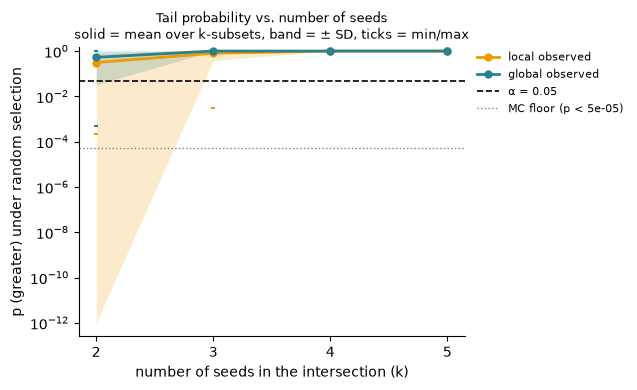

In [20]:
plot_tail_prob_by_k({"local": df_local_list, "global": df_global_list}, pool=POOL)

In [21]:
for name, df_list in [("local", df_local_list), ("global", df_global_list)]:
    overlap, common = overlap_matrix(df_list, labels=SEEDS)
    print(f"--- {name} ---")
    print(overlap)
    print(f"{len(common)} genes in all {len(df_list)} seeds:", sorted(common)[:10], "\n")

--- local ---
    40  41  42  43  44
40  12   0   3   3   3
41   0   5   1   0   0
42   3   1  16   4   3
43   3   0   4  15   2
44   3   0   3   2   8
0 genes in all 5 seeds: [] 

--- global ---
    40  41  42  43  44
40   4   1   0   0   0
41   1  10   2   0   2
42   0   2  15   4   0
43   0   0   4  19   1
44   0   2   0   1   9
0 genes in all 5 seeds: [] 



In [22]:
# Which genes both decoders pick up, for one seed. The local/global split is only
# interpretable per model, never pooled over seeds.
i_seed = SEEDS.index(SEED)
for k, v in local_global_split(df_local_list[i_seed], df_global_list[i_seed]).items():
    print(f"  {k:14s} ({len(v):3d}): {v[:12]}")

  shared         (  5): ['REG1A', 'FGFR1', 'VIM', 'SERPINA3', 'HLA-C']
  unique_local   ( 10): ['APP', 'AZU1', 'DDR1', 'EZR', 'HSPB1', 'KRT18', 'MEG3', 'NPPC', 'PRSS2', 'RPL21']
  unique_global  ( 14): ['ARF1', 'BCL2L1', 'CD24', 'CD44', 'CDH1', 'DUSP5', 'EIF5A', 'INS', 'MALAT1', 'PSAP', 'RPL32', 'SOD2']


## Multi-scale Moran's I: which dimensions are local, which are global

The embedding dimensions are handed to `interscale.tl.moran_scale` as features, so they are
ranked on the same footing as genes. `local_index = slope_local - slope_global` is positive
for a dimension that loses its autocorrelation inside small neighbourhoods and negative for
one that holds it to tissue scale.

In [23]:
import interscale as isc

CONDITION = "T1D"
N_TOP = 5

# Subset FIRST, then build the embedding object: dim_embedding_adata materialises
# n_cells x 2*n_embed float64, which over all 386k cells and n_embed 128 is ~790 MB.
adata_cond = adata[adata.obs[CONDITION_KEY] == CONDITION].copy()
adata_emb = dim_embedding_adata(adata_cond, SEED, spatial_key="spatial")
print(adata_emb.shape, "| dims:", adata_emb.var["emb_type"].value_counts().to_dict())

local_dims = dim_names("local", dims_used["local"][SEED])
global_dims = dim_names("global", dims_used["global"][SEED])
print("local ", local_dims)
print("global", global_dims)

(225288, 256) | dims: {'local': 128, 'global': 128}
local  ['dim_local_35', 'dim_local_72', 'dim_local_43', 'dim_local_58', 'dim_local_99', 'dim_local_114', 'dim_local_108', 'dim_local_22', 'dim_local_13', 'dim_local_126', 'dim_local_68', 'dim_local_38', 'dim_local_51', 'dim_local_39', 'dim_local_123', 'dim_local_50', 'dim_local_77', 'dim_local_1', 'dim_local_27']
global ['dim_global_72', 'dim_global_35', 'dim_global_52', 'dim_global_22', 'dim_global_99', 'dim_global_77', 'dim_global_126', 'dim_global_123', 'dim_global_58', 'dim_global_114', 'dim_global_71', 'dim_global_108', 'dim_global_68', 'dim_global_16', 'dim_global_101', 'dim_global_8', 'dim_global_88', 'dim_global_91', 'dim_global_44', 'dim_global_97', 'dim_global_3']


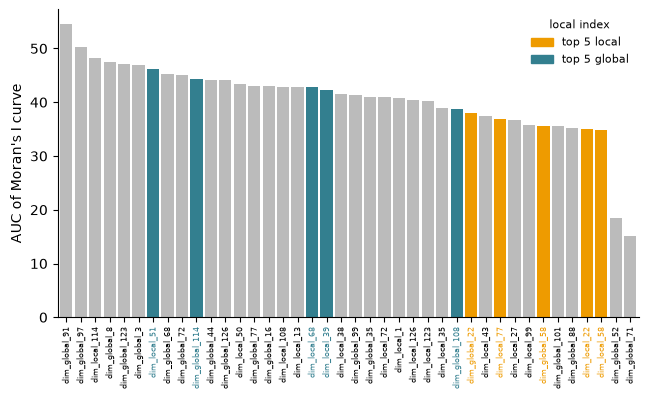

In [24]:
# `genes=` restricts the Moran computation to the kept dimensions. Without it this is 256
# features over ~190k cells at five neighbourhood sizes, which is not worth the wall clock.
isc.tl.moran_scale(
    adata_emb,
    library_key=SAMPLE_KEY,
    genes=local_dims + global_dims,
)
isc.pl.moran_auc(adata_emb, n_top=N_TOP)

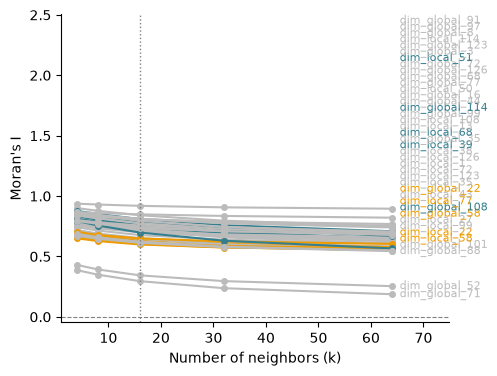

In [25]:
isc.pl.moran_curves(adata_emb, genes=local_dims + global_dims, n_top=N_TOP)

## Does a dimension look like the genes it loads on?

One row per dimension the local index calls most local or most global: the dimension itself
on the left, the three genes at the top of its loadings to the right, same cells. Each gene
panel carries the Pearson r between that gene and the dimension over the cells drawn, which
is the unsmoothed number behind the visual impression.

In [26]:
top_local, top_global = isc.pl.top_local_global(
    adata_emb, n_top=N_TOP, features=local_dims + global_dims
)
print("most local :", top_local)
print("most global:", top_global)

most local : ['dim_local_22', 'dim_global_22', 'dim_local_58', 'dim_global_58', 'dim_local_77']
most global: ['dim_global_114', 'dim_global_108', 'dim_local_39', 'dim_local_68', 'dim_local_51']


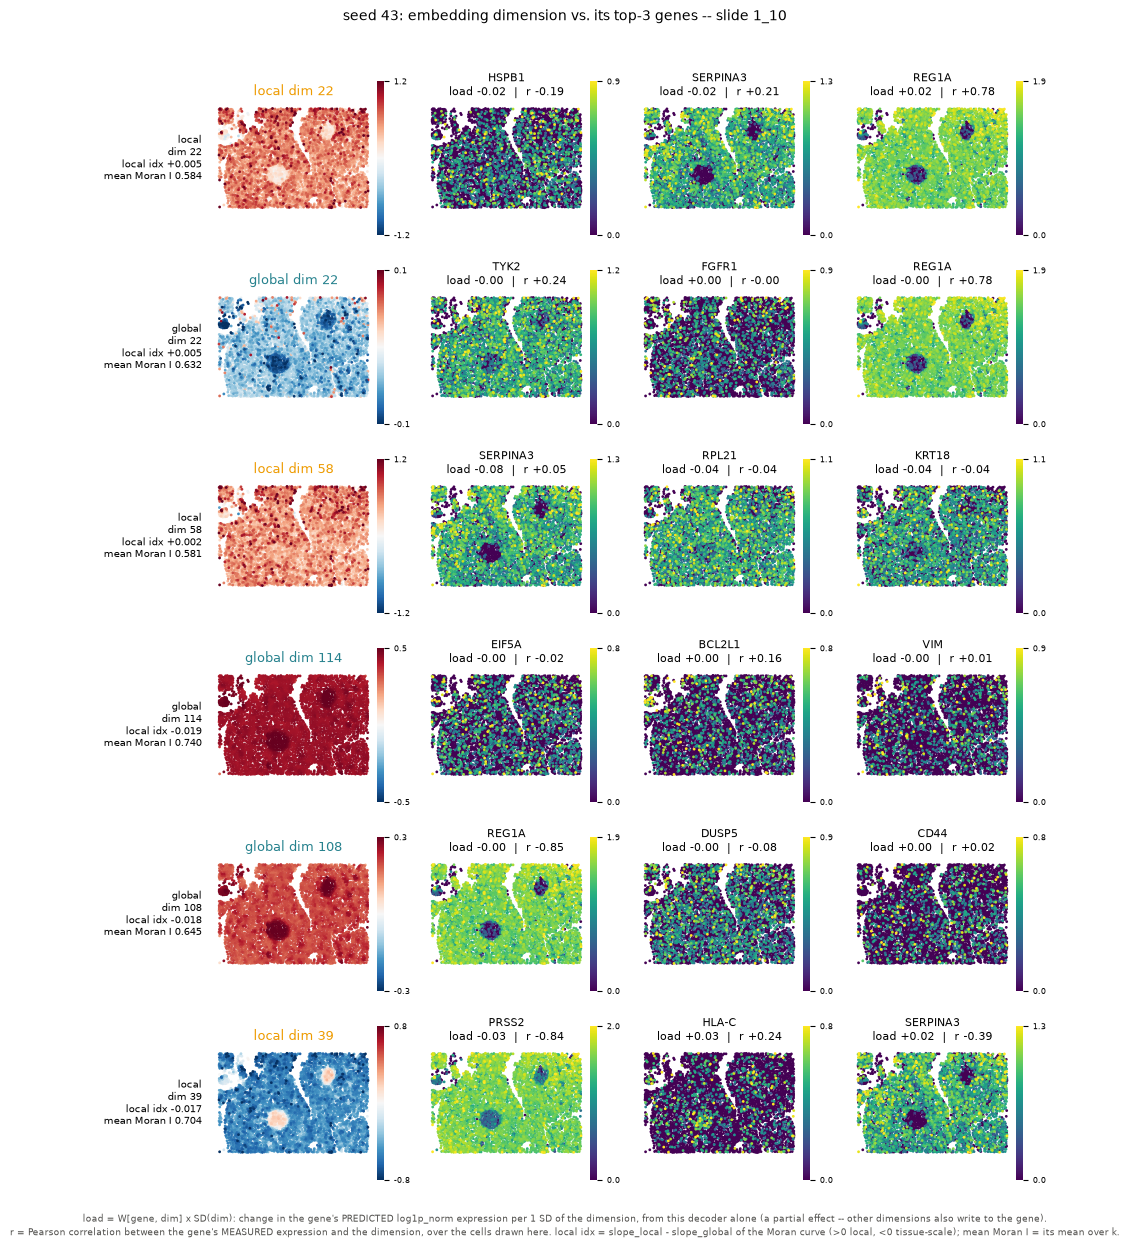

In [27]:
N_PANEL = 3
dfs_seed = {"local": df_local_list[i_seed], "global": df_global_list[i_seed]}
panels = top_local[:N_PANEL] + top_global[:N_PANEL]

T1D_FOV = slides["T1D"]
fig, dim_gene_table = plot_dim_gene_spatial(
    adata,
    panels,
    dfs_seed,
    SEED,
    n_genes=3,
    layer_key=LAYER_KEY,
    sample=T1D_FOV,
    sample_key=SAMPLE_KEY,
    stats=adata_emb.uns["moran_scale"]["stats"],
    size=4,
    save=RESULTS_DIR / f"dim_vs_top_genes_seed{SEED}_{T1D_FOV}.pdf",
)
plt.show()

In [28]:
dim_gene_table.sort_values(["which", "dim", "rank"]).round(3)

,which,dim,rank,gene,loading,pearson_r,gene_sd,loading_std
3,global,22,1,TYK2,-0.004,0.238,0.454,-0.008
4,global,22,2,FGFR1,0.003,-0.000,0.251,0.012
5,global,22,3,REG1A,-0.003,0.776,0.454,-0.007
12,global,108,1,REG1A,-0.003,-0.855,0.454,-0.007
13,global,108,2,DUSP5,-0.002,-0.077,0.308,-0.008
14,global,108,3,CD44,0.002,0.025,0.218,0.011
9,global,114,1,EIF5A,-0.002,-0.021,0.258,-0.007
10,global,114,2,BCL2L1,0.002,0.157,0.234,0.008
11,global,114,3,VIM,-0.002,0.006,0.280,-0.006
0,local,22,1,HSPB1,-0.023,-0.191,0.288,-0.080


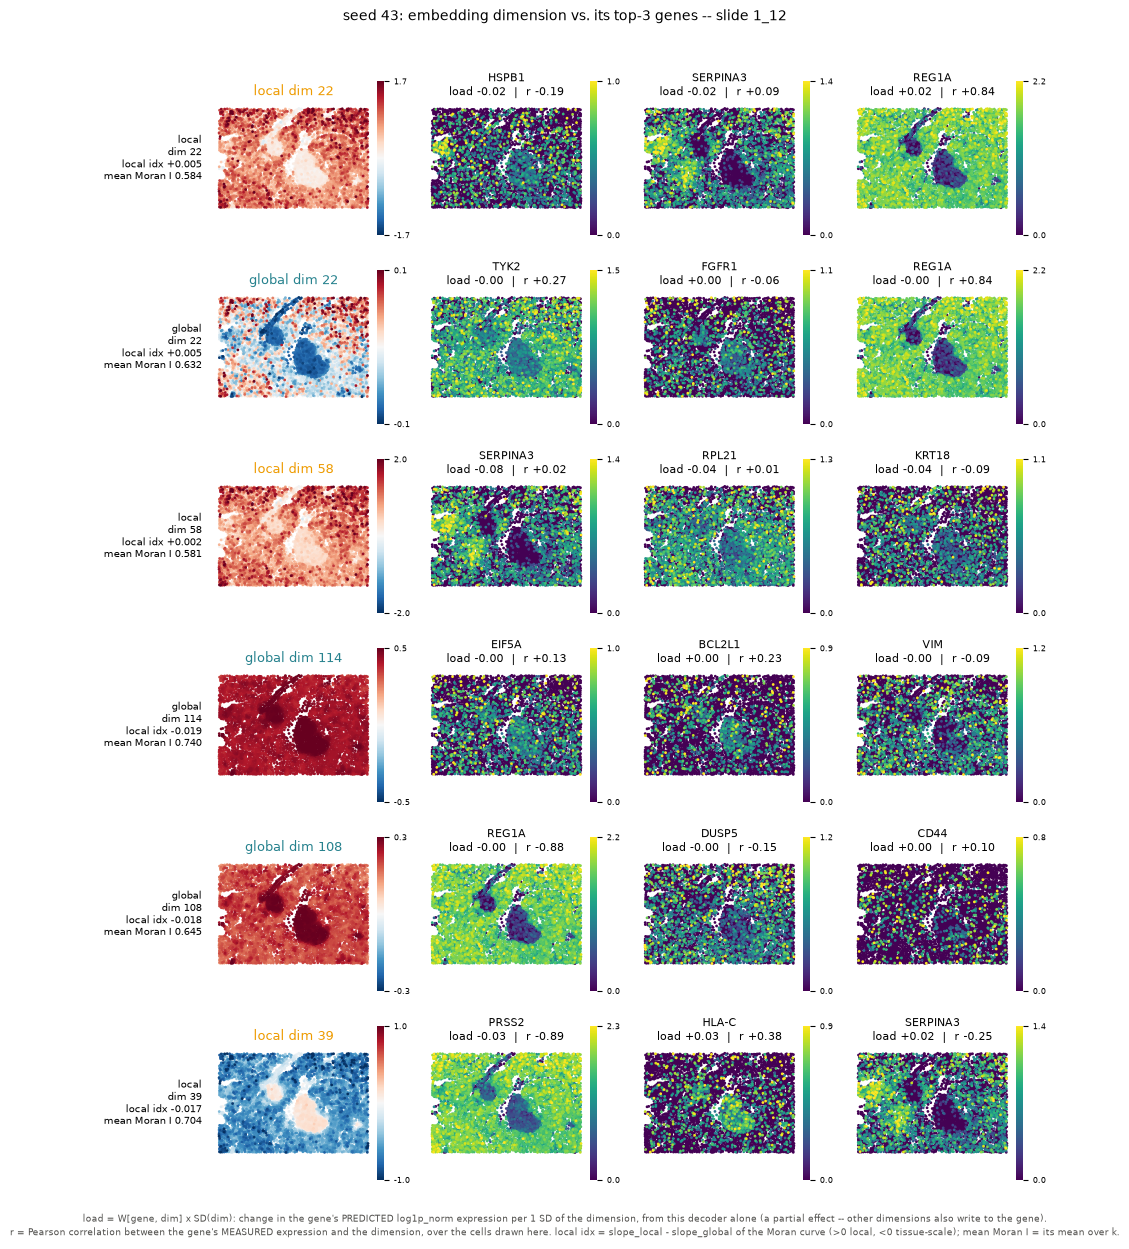

In [29]:
# The same dimensions on the ND fov. These were ranked on T1D, so this is the
# out-of-condition look at them, not a second measurement.
fig, _ = plot_dim_gene_spatial(
    adata, panels, dfs_seed, SEED,
    n_genes=3, layer_key=LAYER_KEY,
    sample=slides["Ctrl"], sample_key=SAMPLE_KEY,
    stats=adata_emb.uns["moran_scale"]["stats"], size=4,
)
plt.show()

## The negative → positive anchor axis

`t = d_neg / (d_neg + d_pos)`: 0 at a dimension's negative pole, 1 at its positive one, built
from two `find_anchor_cells` calls per section. Genes with a positive loading should rise
toward 1 and negative ones toward 0.

The local component reaches `radius x num_layers` here, which with this sweep's
`local_component.num_layers = 1` is **110 x 1 = 110 units** against legnini23's 400 — so the
shaded end-bands on the profile panels are much narrower, and correspondingly more of the
axis lies beyond what a local model could carry. `REACH` is read off `cfg0`, so it follows
the sweep rather than this comment.

In [30]:
from interscale.tl import local_reach_um

from src.dimension_axis import (
    axis_gene_stats,
    axis_map,
    axis_profiles,
    dimension_axis,
    plot_dimension_axis,
    scan_two_pole_dims,
    z_within_slide,
)

REACH = local_reach_um(cfg0)
AXIS_FIG_DIR = Path(BASE_DIR_REPO) / "figures" / DATA / f"dimension_axis_{MASKING}"
AXIS_FIG_DIR.mkdir(parents=True, exist_ok=True)

COND_FOVS = sorted(adata_cond.obs[SAMPLE_KEY].astype(str).unique())
print(f"local reach {REACH:g} | {len(COND_FOVS)} {CONDITION} sections | example {EXAMPLE_FOVS}")
print(f"figures -> {AXIS_FIG_DIR}")

local reach 110 | 39 T1D sections | example ['1_12', '1_10']
figures -> /home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/figures/melton25/dimension_axis_gene


**The gate.** Per dimension, on how many sections do the two poles end up far enough apart
to be worth measuring between? `n_slides_two_foci` is usually every section — a quantile
tail always exists — while `n_slides_both` additionally requires the poles to be at least
`REACH` apart.

In [31]:
GLOBAL_DIMS = [int(d) for d in dims_used["global"][SEED]]

gate = scan_two_pole_dims(
    adata_cond,
    f"{SEED}_global_emb",
    GLOBAL_DIMS,
    quantiles=(0.90, 0.95),
    sample_key=SAMPLE_KEY,
    samples=COND_FOVS,
    link_radius=REACH,
    min_cluster_size=15,
    verbose=False,
)
gate.sort_values(["n_slides_both", "median_sep_min"], ascending=False).round(3)

,dim,quantile,n_slides_both,n_slides_two_foci,n_slides_any,median_sep_min,median_frac_corridor,slides_both
19,114,0.95,39,39,39,683.556,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."
16,58,0.90,39,39,39,466.744,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."
34,91,0.90,39,39,39,436.497,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."
8,99,0.90,39,39,39,393.935,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."
10,77,0.90,39,39,39,316.337,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."
12,126,0.90,39,39,39,298.617,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."
6,22,0.90,39,39,39,291.204,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."
30,8,0.90,39,39,39,269.268,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."
28,101,0.90,39,39,39,268.017,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."
0,72,0.90,39,39,39,220.844,1.0,"[1_1, 1_10, 1_11, 1_2, 1_3, 1_4, 1_5, 1_6, 1_7..."


In [32]:
best = gate.sort_values(["n_slides_both", "median_sep_min"], ascending=False).iloc[0]
AXIS_DIM, AXIS_Q = int(best["dim"]), float(best["quantile"])
print(f"axis on global dim {AXIS_DIM} at quantile {AXIS_Q:.2f}: "
      f"{int(best['n_slides_both'])}/{len(COND_FOVS)} sections usable "
      f"({int(best['n_slides_two_foci'])} had two foci at all), "
      f"median separation {best['median_sep_min']:.0f}")

axis on global dim 114 at quantile 0.95: 39/39 sections usable (39 had two foci at all), median separation 684


In [33]:
axis = dimension_axis(
    adata_cond,
    f"{SEED}_global_emb",
    AXIS_DIM,
    sample_key=SAMPLE_KEY,
    samples=COND_FOVS,
    quantile=AXIS_Q,
    link_radius=REACH,
    min_cluster_size=15,
    local_reach=REACH,
    key_added=f"{SEED}_axis_dim{AXIS_DIM}",
)
print("usable sections:", len(axis.slides_with_both))
axis.per_slide.round(3).head(12)

usable sections: 38


,sample,n_pos,n_neg,has_both,separated,z_neg,z_pos,z_span,z_med,n_axis,sep_min,t_reach,n_corridor,frac_corridor
0,1_1,196,15,True,True,0.403,0.501,0.098,0.439,4499,2754.695,0.040,4499,1.0
1,1_10,204,52,True,True,0.399,0.503,0.104,0.433,4423,799.090,0.138,4423,1.0
2,1_11,155,42,True,True,0.317,0.505,0.188,0.418,3493,967.650,0.114,3493,1.0
3,1_2,218,58,True,True,0.400,0.502,0.101,0.438,4450,983.781,0.112,4450,1.0
4,1_3,190,34,True,True,0.413,0.498,0.085,0.442,4000,1373.399,0.080,4000,1.0
5,1_4,196,51,True,True,0.406,0.494,0.088,0.441,4274,1742.574,0.063,4274,1.0
6,1_5,16,51,True,True,0.421,0.478,0.057,0.447,3895,2968.910,0.037,3895,1.0
7,1_6,89,65,True,True,0.410,0.484,0.074,0.440,4206,2963.155,0.037,4206,1.0
8,1_7,220,81,True,True,0.406,0.497,0.091,0.437,4807,1837.656,0.060,4807,1.0
9,1_8,150,73,True,True,0.401,0.486,0.084,0.435,4657,612.171,0.180,4657,1.0


drawing: ['1_10']


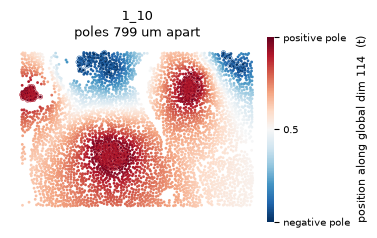

In [34]:
# The axis in space, drawn the way signed_distance_map draws the one-pole distance: every cell
# coloured, both anchors ringed.
AXIS_FOVS = [s for s in EXAMPLE_FOVS if s in axis.slides_with_both] or axis.slides_with_both[:2]
print("drawing:", AXIS_FOVS)

fig, _ = axis_map(
    adata_cond,
    axis,
    samples=AXIS_FOVS,
    sample_key=SAMPLE_KEY,
    size=4,
    save=AXIS_FIG_DIR / f"dim{AXIS_DIM}_axis_map.pdf",
)

In [35]:
WEIGHTS = top_genes_per_dim(dfs_seed["global"], AXIS_DIM, 3)
print(WEIGHTS.round(3).to_string())

profiles, pooled = axis_profiles(
    adata_cond,
    list(WEIGHTS.index),
    axis,
    layer=LAYER_KEY,
    sample_key=SAMPLE_KEY,
    samples=axis.slides_with_both,
    n_bins=12,
    min_cells=15,
)
print("profiled:", len(profiles), "sections")

EIF5A    -0.002
BCL2L1    0.002
VIM      -0.002


profiled: 38 sections


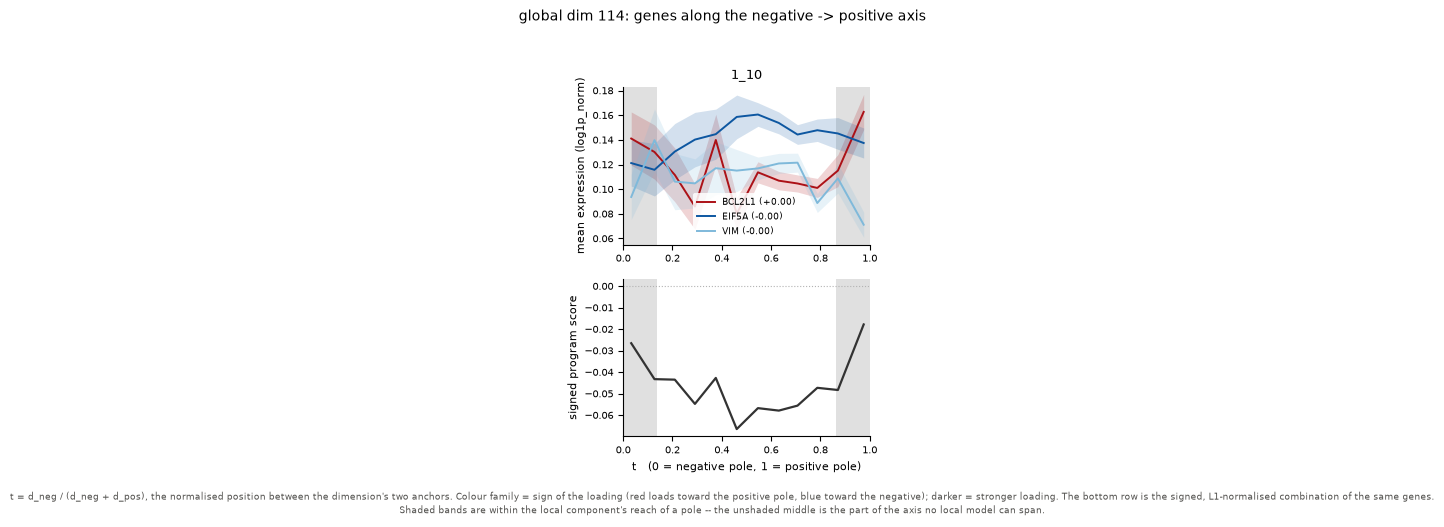

In [36]:
fig, _ = plot_dimension_axis(
    adata_cond, axis, profiles, WEIGHTS,
    samples=AXIS_FOVS,
    save=AXIS_FIG_DIR / f"dim{AXIS_DIM}_axis_examples.pdf",
)

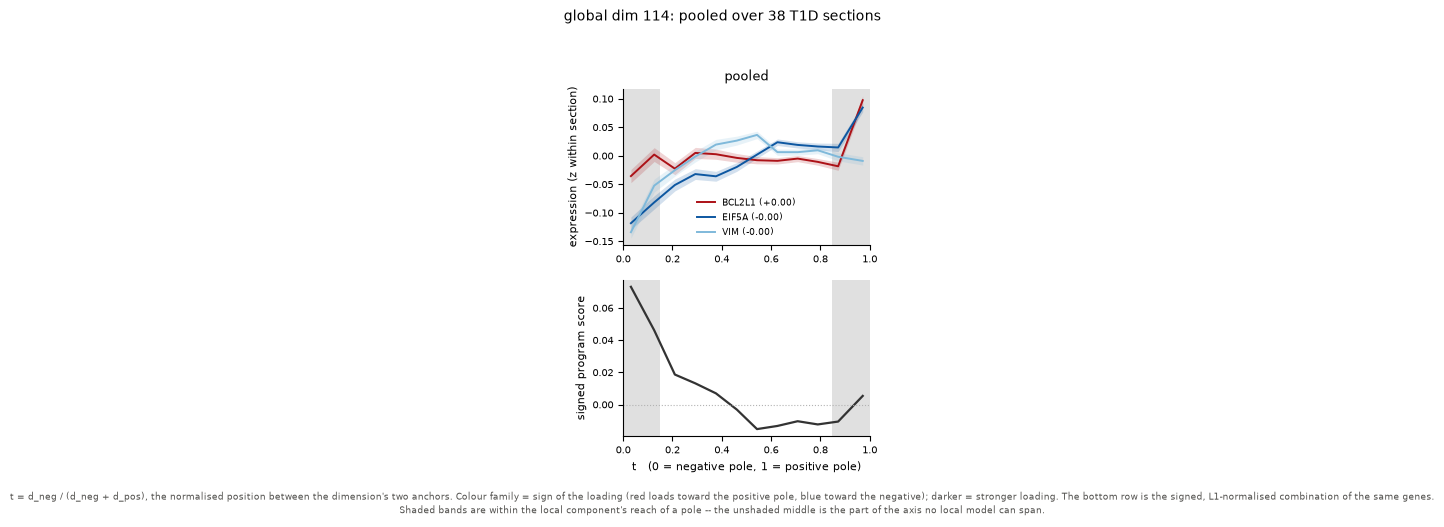

In [37]:
# Pooled over every usable section, on the z-within-section layer: sections differ in overall
# intensity, so pooling raw would let the brightest one set the curve.
fig, _ = plot_dimension_axis(
    adata_cond, axis, pooled, WEIGHTS,
    samples=None,
    ylabel="expression (z within section)",
    title=f"global dim {AXIS_DIM}: pooled over {len(axis.slides_with_both)} {CONDITION} sections",
    save=AXIS_FIG_DIR / f"dim{AXIS_DIM}_axis_pooled.pdf",
)

In [38]:
# Ignore `spearman_p`: at this cell count a rank correlation of 0.01 returns p = 0, so the
# p-value is reporting n, not an effect. Read `spearman_r` against the other genes.
stats_axis = axis_gene_stats(
    adata_cond, list(WEIGHTS.index), axis, WEIGHTS, pooled,
    layer=LAYER_KEY, sample_key=SAMPLE_KEY, samples=axis.slides_with_both,
)
stats_axis.to_csv(AXIS_FIG_DIR / f"dim{AXIS_DIM}_axis_gene_stats.csv", index=False)
stats_axis.round(3)

,gene,loading,spearman_r,spearman_p,binned_slope,sign_agrees,n_cells
0,EIF5A,-0.002,0.058,0.0,0.168,False,218916
1,BCL2L1,0.002,0.022,0.0,0.054,True,218916
2,VIM,-0.002,0.008,0.0,0.087,False,218916


## What this notebook does and does not show

It runs the legnini23 stability pipeline end to end on melton25, sharing the selection code
rather than reimplementing it, so the two datasets stay comparable.

What it cannot show, on sweep `k0y6dgk6`, is whether InterScale's gene loadings are stable:
all five checkpoints reconstruct slightly below the constant per-gene mean (val_r2
-0.0054 +/- 0.0014), so their decoders carry no programme to be stable about. The same holds
for the superseded `4ztsppu8`. The retrain changed data, mask rate, monitor and schedule but
kept sweep sio2fsjm's architecture, which was selected on the old 979-gene data; the next step
is a stage-1 search on the current data (`hyperparameters_melton25_genemask.yaml`, ranked on
`val_r2`), and a seed sweep of its winner. Re-read the health check cell after that retrain:
once the median clears the within-cell bar, every number below it becomes interpretable without
any other change to this notebook.

**What the run produced (2026-11-01, seeds 40–44).** No gene is selected in all five seeds,
for either decoder (0 local, 0 global), and none in any four; three-seed intersections are
0.2 (local) and 0.0 (global) on average. Pairs share 1.9 local / 1.0 global genes against
~0.18 expected by chance. That pairwise excess is not evidence of stability here: the
`loading_x_sd` ranking favours high-variance genes, and the genes that recur (REG1A,
SERPINA3, PRSS2, HLA-C, VIM) are the panel's most variable acinar and inflammatory genes, which
a decoder at the mean predictor still ranks high because the score multiplies by sd. Per seed, each decoder's
median per-gene test r2 is between -0.37 and -1.73.